In [1]:
import os
import numpy as np
import shutil
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.stats import linregress

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# @title

# def lines_print(img_path, line_locations, i, line_dist_dic, label):

#   # make a list of the r_2 values
#   r_squared_list = []

#   # make a list of the line_dist_dic keys
#   line_keys = list(line_dist_dic.keys())



#   img = mpimg.imread(
#     img_path
#   )
#   image = plt.imshow(img, cmap = "grey")

#   counter = 0
#   for col in line_locations.columns[1:]:
#     x1,y1,x2,y2 = line_locations[col][i].split(",")
#     x1 = float(x1)
#     x2 = float(x2)
#     y1 = float(y1)
#     y2 = float(y2)

#     x_vals = [x1,x2]
#     y_vals = [y1,y2]


#     plt.plot(x_vals,y_vals)


#     # load in the coordinates of the spots for each line
#     x_spots = line_dist_dic[line_keys[counter]]
#     y_spots = line_dist_dic[line_keys[counter+1]]
#     plt.scatter(x_spots,y_spots)

#     # run linear regressions on x and y vals
#     # if linear regression doesn't work because there are no or one point, set rsquared == 1
#     # try:
#     result = linregress(x_spots, y_spots)
#     r_value = result.rvalue
#     if np.isnan(r_value):
#       r_value = 1
#     r_squared = r_value ** 2
#     r_squared_list.append(r_squared)


#     counter += 2


#   plt.title(label)
#   plt.show()

#   return r_squared_list


# def point_to_line_distance(px, py, x1, y1, x2, y2): # from ChatGPT
#     numerator = abs((y2 - y1)*px - (x2 - x1)*py + x2*y1 - y2*x1)
#     denominator = np.sqrt((y2 - y1)**2 + (x2 - x1)**2)
#     return numerator / denominator


# # find the linearity of spots in each line
# def spot_linearity(line_locations, spots_df, i):


#   # make a dictionary with lists of x and y values for each line

#   min_line_dic = {
#                     "0x": [], "0y" : [],
#                     "1x": [], "1y" : [],
#                     "2x": [], "2y" : [],
#                     "3x": [], "3y" : [],
#                     "4x": [], "4y" : [],
#                     }

#   # iterate through all points and find the shortest distance to this line, ignoring the first datapoint as that is an overall measurement of the entire image
#   for j in range(1, spots_df.shape[0]):
#     spot_x = float(spots_df["X"][j])
#     spot_y = spots_df["Y"][j]

#     # set a list that hass all the distances in it
#     dist_list = []


#     for col in line_locations.columns[1:]:
#       x1,y1,x2,y2 = line_locations[col][i].split(",")
#       x1 = float(x1)
#       x2 = float(x2)
#       y1 = float(y1)
#       y2 = float(y2)

#       # # the slope of a perpendicular line is the inverse reciprocal
#       # perp_slope = -1/line_slope

#         # try using this function from chatGPT first
#         # it works by using the point line formula and subbing for x and y,
#         # https://en.wikipedia.org/wiki/Distance_from_a_point_to_a_line?
#       spot_distance = point_to_line_distance(
#             spot_x, spot_y,
#             x1, y1,
#             x2, y2
#         )


#       # generate the list of all distances to a line
#       dist_list.append(spot_distance)

#     # identify the index of the minimal distance line
#     min_line = dist_list.index(min(dist_list))
#     min_dist_squared = (min(dist_list))**2
#     min_dist_squared


#     # add this x and y values to the dictionary
#     min_line_dic[f"{min_line}x"].append(spot_x)
#     min_line_dic[f"{min_line}y"].append(spot_y)


#   return min_line_dic

# r_squared_lists = []

# labels = ["B","C","D","E","F","G","H","I","J","K","L","M","N","O","B","C","D","E","F","G","H","I","J","K","L","M","N","O"]

# # import line coordinates for each petal

# line_locations = pd.read_excel('/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Generating_vertical_lines/Line_Coordinates.xlsx')

# # make a list of the proessed images
# image_dir = sorted(os.listdir("/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Processed_images/"))

# dir = '/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Extracted_Features'
# feat_files = os.listdir(dir)

# for i,filename in enumerate(['00.csv', '01.csv', '02.csv', '03.csv', '04.csv', '05.csv','06.csv', '07.csv', '08.csv', '09.csv', '10.csv', '11.csv', '12.csv', '13.csv', '14.csv', '15.csv', '16.csv', '17.csv', '18.csv', '19.csv', '20.csv', '21.csv', '22.csv', '23.csv', '24.csv', '25.csv', '26.csv', '27.csv']):
# #for i,filename in enumerate(['00.csv']):
#   # load df of spots
#   spots_df = pd.read_csv(f'{dir}/{filename}')

#   # feed the spot data and the line coordinates to the
#   line_dist_dic =  spot_linearity(line_locations, spots_df, i)

#   # define the label
#   if i/14 < 1:
#     label = f"{labels[i]} Real"

#   else:
#     label = f"{labels[i]} Simulated"



#   # print the image with the lines on it
#   img_path = f'/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Processed_images/{image_dir[i]}'
#   print(image_dir[i])
#   r_squared_list = lines_print(img_path, line_locations ,i, line_dist_dic, label)
#   r_squared_lists.append(r_squared_list)




In [3]:

def lines_print(img_path, line_locations, i, line_dist_dic, label):

  # make a list of the r_2 values
  r_squared_list = []

  # make a list of the line_dist_dic keys
  line_keys = list(line_dist_dic.keys())



  img = mpimg.imread(
    img_path
  )
  image = plt.imshow(img, cmap = "grey")

  counter = 0
  for col in line_locations.columns[1:]:
    x1,y1,x2,y2 = line_locations[col][i].split(",")
    x1 = float(x1)
    x2 = float(x2)
    y1 = float(y1)
    y2 = float(y2)

    x_vals = [x1,x2]
    y_vals = [y1,y2]


    plt.plot(x_vals,y_vals)


    # load in the coordinates of the spots for each line
    x_spots = line_dist_dic[line_keys[counter]]
    y_spots = line_dist_dic[line_keys[counter+1]]
    plt.scatter(x_spots,y_spots)

    # run linear regressions on x and y vals
    # if linear regression doesn't work because there are no or one point, set rsquared == 1
    # # try:
    # result = linregress(x_spots, y_spots)
    # r_value = result.rvalue
    # if np.isnan(r_value):
    #   r_value = 1
    # r_squared = r_value ** 2
    # r_squared_list.append(r_squared)


    counter += 2


  plt.title(label)
  # plt.savefig(f"/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Flowers_with_lines_and_spot_centroids/{label}", dpi=300, bbox_inches="tight")
  plt.show()
  plt.close()




def point_to_line_distance(px, py, x1, y1, x2, y2): # from ChatGPT
    numerator = abs((y2 - y1)*px - (x2 - x1)*py + x2*y1 - y2*x1)
    denominator = np.sqrt((y2 - y1)**2 + (x2 - x1)**2)
    return numerator / denominator


# find the linearity of spots in each line
def spot_linearity(line_locations, spots_df, i):


  # make a dictionary with lists of x and y values for each line

  min_dist_dic = {
                  0:[],
                  1:[],
                  2:[],
                  3:[],
                  4:[],
  }

  min_line_dic = {
                    "0x": [], "0y" : [],
                    "1x": [], "1y" : [],
                    "2x": [], "2y" : [],
                    "3x": [], "3y" : [],
                    "4x": [], "4y" : [],
                    }

  # iterate through all points and find the shortest distance to this line, ignoring the first datapoint as that is an overall measurement of the entire image
  for j in range(1, spots_df.shape[0]):
    spot_x = float(spots_df["X"][j])
    spot_y = spots_df["Y"][j]

    # set a list that hass all the distances in it
    dist_list = []


    for col in line_locations.columns[1:]:
      x1,y1,x2,y2 = line_locations[col][i].split(",")
      x1 = float(x1)
      x2 = float(x2)
      y1 = float(y1)
      y2 = float(y2)

      # # the slope of a perpendicular line is the inverse reciprocal
      # perp_slope = -1/line_slope

        # try using this function from chatGPT first
        # it works by using the point line formula and subbing for x and y,
        # https://en.wikipedia.org/wiki/Distance_from_a_point_to_a_line?
      spot_distance = point_to_line_distance(
            spot_x, spot_y,
            x1, y1,
            x2, y2
        )


      # generate the list of all distances to a line
      dist_list.append(spot_distance)

    # identify the index of the minimal distance line
    min_line = dist_list.index(min(dist_list))

    # add the distance to a dictionary
    min_dist_dic[min_line].append(min(dist_list))

    # add this x and y values to the dictionary
    min_line_dic[f"{min_line}x"].append(spot_x)
    min_line_dic[f"{min_line}y"].append(spot_y)


  rmsd_spots = []
  # iterate through the min_dist_dic keys and turn it into the RMSE of each
  for k in range(5):
    spot_dist_arr = np.array(min_dist_dic[k])

    # take the RMSD of each line group and add it to the list
    spot_rmsd = np.sqrt(np.mean(spot_dist_arr ** 2))

    # check for divide by zero. If there are no spots, just set the rmsd to zero
    if np.isnan(spot_rmsd):
      rmsd_spots.append(0)

    else:
      rmsd_spots.append(spot_rmsd)


  return min_line_dic, rmsd_spots

rmsd_lists = []

labels = ["B","C","D","E","F","G","H","I","J","K","L","M","N","O","B","C","D","E","F","G","H","I","J","K","L","M","N","O"]

# import line coordinates for each petal

line_locations = pd.read_excel('/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Generating_vertical_lines/Line_Coordinates.xlsx')

# make a list of the proessed images
image_dir = sorted(os.listdir("/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Processed_images/"))

dir = '/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Extracted_Features'
feat_files = os.listdir(dir)

for i,filename in enumerate(['00.csv', '01.csv', '02.csv', '03.csv', '04.csv', '05.csv','06.csv', '07.csv', '08.csv', '09.csv', '10.csv', '11.csv', '12.csv', '13.csv', '14.csv', '15.csv', '16.csv', '17.csv', '18.csv', '19.csv', '20.csv', '21.csv', '22.csv', '23.csv', '24.csv', '25.csv', '26.csv', '27.csv']):
#for i,filename in enumerate(['00.csv']):
  # load df of spots
  spots_df = pd.read_csv(f'{dir}/{filename}')

  # feed the spot data and the line coordinates to the
  line_dist_dic,rmsd_list =  spot_linearity(line_locations, spots_df, i)

  rmsd_lists.append(rmsd_list)

  # define the label
  if i/14 < 1:
    label = f"{labels[i]} Real"

  else:
    label = f"{labels[i]} Simulated"



  # print the image with the lines on it
  img_path = f'/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Processed_images/{image_dir[i]}'
  print(image_dir[i])
  lines_print(img_path, line_locations ,i, line_dist_dic, label)





Output hidden; open in https://colab.research.google.com to view.

In [4]:
# this code extracts features and makes them into a single array containing mean and std of each feat

def feat_compile(dir,path):

  real_imj_df = {"path":[],"feats_df":[]}

  real_imj_df["path"].append(path)
  real_imj_df["feats_df"].append(pd.read_csv(f'{dir}/{path}'))

  real_df = pd.DataFrame(real_imj_df)

  # real_df = pd.read_csv(f'{dir}/{path}')
  # Add regular features

  # first list is mean, second list is std except for mean and median
  feats = {'Mean':[],'Median':[],'Area':[[],[]], 'X':[[],[]], 'Y':[[],[]], 'Perim.':[[],[]], 'BX':[[],[]],
          'BY':[[],[]], 'Width':[[],[]], 'Height':[[],[]], 'Major':[[],[]], 'Minor':[[],[]],
        'Angle':[[],[]], 'Circ.':[[],[]], 'Feret':[[],[]], 'IntDen':[[],[]], '%Area':[[],[]],
        'RawIntDen':[[],[]], 'FeretX':[[],[]], 'FeretY':[[],[]], 'FeretAngle':[[],[]], 'MinFeret':[[],[]], 'AR':[[],[]],
        'Round':[[],[]], 'Solidity':[[],[]]}



  # iterate through all sims
  for n in range(real_df.shape[0]): # grab the feats dataframe for this sim
    fdf = real_df["feats_df"][n] #iterate through all feats within the feats dictionary

    print("shape", fdf.shape[0])

    for i in range(len(feats.keys())): # select the current feat
      feat = list(feats.keys())[i]

      if feat in ['Mean','Median']: # check for feats that should be added from the overall measurement (first row)
        feats[feat].append(fdf[feat[:]][0])
        # feats[feat].append(fdf[feat][0])

      else:
        if fdf.shape[0] <= 1: # check if the fdf is only one measurement (empty result)
          # feats[feat][0].append(np.mean(np.array(fdf[feat][0]))) # mean of sole measurement
          # feats[feat][1].append(np.std(np.array(fdf[feat][0]))) #std of sole measurement (0)

          # just make the values zero if there is no measuremet
          feats[feat][0].append(0) # mean of sole measurement
          feats[feat][1].append(0) #std of sole measurement (0)


        else:
          feats[feat][0].append(np.mean(np.array(fdf[feat][1:]))) # add mean for each of the rest of the feats using the remaining rows
          feats[feat][1].append(np.std(np.array(fdf[feat][1:]))) # add std for each of the rest of the feats using the remaining rows

  num_spots = []

  for i in range(real_df.shape[0]):
    fdf = real_df["feats_df"][i] #iterate through all feats within the feats dictionary
    if fdf.shape[0] <= 1:
      num_spots.append(0)
    else:
      num_spots.append(fdf.shape[0]-1)

  # feats_df["num_spots_inverted"] = num_spots
  real_df["num_spots"] = num_spots


  for key in list(feats.keys()):
    # if key in ['Mean_inverted','Median_inverted']:
    if key in ['Mean','Median']:
      real_df[key] = feats[key]
    else:
      # feats_df[key + "_inverted_mean"] = feats[key][0]
      # feats_df[key + "_inverted_std"] = feats[key][1]
      real_df[key + "_mean"] = feats[key][0]
      real_df[key + "_std"] = feats[key][1]

  return real_df


counter = 0

imj_df = {}

dir = '/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Extracted_Features'
feat_files = os.listdir(dir)

for i,filename in enumerate(['00.csv', '01.csv', '02.csv', '03.csv', '04.csv', '05.csv','06.csv', '07.csv', '08.csv', '09.csv', '10.csv', '11.csv', '12.csv', '13.csv', '14.csv', '15.csv', '16.csv', '17.csv', '18.csv', '19.csv', '20.csv', '21.csv', '22.csv', '23.csv', '24.csv', '25.csv', '26.csv', '27.csv']):
  feat_array = feat_compile(dir, filename)
  # add the r squared values
  feat_array["rmsd_line_1"] = rmsd_lists[i][0]
  feat_array["rmsd_line_2"] = rmsd_lists[i][1]
  feat_array["rmsd_line_3"] = rmsd_lists[i][2]
  feat_array["rmsd_line_4"] = rmsd_lists[i][3]
  feat_array["rmsd_line_5"] = rmsd_lists[i][4]
  feat_array["rmsd_mean_1_5"] = (rmsd_lists[i][4] +  rmsd_lists[i][0]) / 2
  feat_array["rmsd_mean_2_4"] = (rmsd_lists[i][3] +  rmsd_lists[i][1]) / 2
  feat_array["rmsd_mean"] = np.mean(rmsd_lists[i])
  print(rmsd_lists[i])



  imj_df[filename] = feat_array


  print(counter)
  counter += 1

shape 90
[np.float64(29.22588289879149), np.float64(18.17966779281207), np.float64(27.866523928345224), np.float64(23.546649033647856), 0]
0
shape 91
[np.float64(6.033111970773828), np.float64(41.465647845717605), np.float64(32.551620498585606), np.float64(22.565992767408904), np.float64(24.66185087016289)]
1
shape 22
[np.float64(29.763658003744894), np.float64(36.854318523257554), np.float64(21.093795854066705), np.float64(36.79201269209076), np.float64(27.76978535686247)]
2
shape 21
[np.float64(26.507985134635476), np.float64(35.03016430548609), np.float64(31.618974303414713), np.float64(43.632128000503215), np.float64(42.252219868784294)]
3
shape 10
[np.float64(21.187579246145884), 0, np.float64(44.45261673193701), 0, np.float64(28.771480436725426)]
4
shape 1
[0, 0, 0, 0, 0]
5
shape 5
[0, np.float64(25.341922709901382), 0, np.float64(15.391032773683945), 0]
6
shape 48
[np.float64(27.564796981029595), np.float64(20.11742036607487), np.float64(27.142126228415794), np.float64(19.677338

In [5]:
imj_df.keys()

dict_keys(['00.csv', '01.csv', '02.csv', '03.csv', '04.csv', '05.csv', '06.csv', '07.csv', '08.csv', '09.csv', '10.csv', '11.csv', '12.csv', '13.csv', '14.csv', '15.csv', '16.csv', '17.csv', '18.csv', '19.csv', '20.csv', '21.csv', '22.csv', '23.csv', '24.csv', '25.csv', '26.csv', '27.csv'])

In [ ]:
# cols = [
#       "num_spots",
#       "Area_mean",
#       "Area_std",
#       # "X_mean",
#       # "X_std",
#       # "Y_mean",
#       # "Y_std",
#       # "Width_mean",
#       # "Width_std",
#       # "Height_mean",
#       # "Height_std",
#       "Round_mean",
#       "Round_std",
#       "rmsd_line_1",
#       "rmsd_line_2",
#       "rmsd_line_3",
#       "rmsd_line_4",
#       "rmsd_line_5",
#       # "rmsd_mean_1_5",
#       # "rmsd_mean_2_4"
#       # "rmsd_mean"
#   ]


In [6]:
# iterate through all sims and turn into a numpy array

cols = [
      "num_spots",
      "Area_mean",
      "Area_std",
      "Round_mean",
      "Round_std",
      "rmsd_line_1",
      "rmsd_line_2",
      "rmsd_line_3",
      "rmsd_line_4",
      "rmsd_line_5"
  ]





# cols = imj_df['00.csv'].columns[2:]


feats_arr = np.zeros((len(list(imj_df.keys())),len(cols)))

for i,key in enumerate(list(imj_df.keys())):
  feats_arr[i] = imj_df[key][cols]


# weighting different features:





In [8]:
feats_arr_df = pd.DataFrame(feats_arr)
feats_arr_df

,0,1,2,3,4,5,6,7,8,9
0,89.0,101.202247,93.685486,0.649079,0.163655,29.225883,18.179668,27.866524,23.546649,0.000000
1,90.0,361.588889,892.403109,0.548989,0.208993,6.033112,41.465648,32.551620,22.565993,24.661851
2,21.0,3152.952381,10988.254259,0.493619,0.226500,29.763658,36.854319,21.093796,36.792013,27.769785
3,20.0,5227.150000,19793.975185,0.632850,0.275799,26.507985,35.030164,31.618974,43.632128,42.252220
4,9.0,14878.777778,39171.131336,0.567333,0.149686,21.187579,0.000000,44.452617,0.000000,28.771480
5,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,4.0,99.500000,89.234242,0.690500,0.146121,0.000000,25.341923,0.000000,15.391033,0.000000
7,47.0,1050.042553,1800.308767,0.545745,0.257645,27.564797,20.117420,27.142126,19.677338,29.500556
8,51.0,108.666667,91.905678,0.582667,0.171193,0.000000,13.026495,27.106559,11.072287,0.000000
9,42.0,220.476190,168.289891,0.589524,0.164705,0.000000,13.608004,30.248404,27.078421,0.000000


In [24]:

# # scale the values
# from sklearn.preprocessing import StandardScaler

# scaler = StandardScaler()

# feats_arr_scaled = scaler.fit_transform(feats_arr)


# # weighting different features: each number corresponds to the subsequengt feature


# weights = [
#         1, # "num_spots"
#         3, # "Area_mean"
#         1, # "Area_std"
#         1, # "Round_mean"
#         1, # "Round_std"
#         1, # "rmsd_line_1"
#         1, # "rmsd_line_2"
#         1, # "rmsd_line_3"
#         1, # "rmsd_line_4"
#         1 # "rmsd_line_5"

# ]


# for i, weight in enumerate(weights):
#   feats_arr_scaled[:,i] *= weight



In [ ]:
# # scale num spots and area by some amount to increase their importance
# scaling_factor = 3
# feats_arr_scaled[i][0] *= scaling_factor
# feats_arr_scaled[i][1] *= scaling_factor
# feats_arr_scaled[i][2] *= scaling_factor

In [25]:
# # compute pairwise RMSD between all 14 real and 14 simulated images

# pairwise_mse = np.zeros((14,14))


# # iterate through real images
# for i in range(0,14):
#   real_feats = feats_arr_scaled[i]
#   counter = 0
#   # iterate through simulated images
#   for j in range(14,28):
#     sim_feats = feats_arr_scaled[j]
#     # real - predicted
#     errors = real_feats - sim_feats

#     sq_errors = errors ** 2

#     mse = np.sqrt(np.mean(sq_errors))


#     # each row corresponds to a real image, each column to a simulated imgae (all 1-14 same as the paper)
#     pairwise_mse[i][counter] = mse
#     counter += 1


In [ ]:
# import numpy as np
# import seaborn as sns
# import matplotlib.pyplot as plt

# plt.figure(figsize=(16,14))

# labels = ["B","C","D","E","F","G","H","I","J","K","L","M","N","O"]

# sns.heatmap(
#     pairwise_mse,
#     cmap='viridis_r',
#     annot=True,      # show values
#     fmt='.3f',        # 2 decimal places
#     xticklabels= labels,
#     yticklabels= labels
# )

# plt.title('Simulation vs Real Flowers Similarity Matrix')


# plt.xlabel("Simulated Patterns")
# plt.ylabel("Real Patterns")

# plt.savefig(
#     "heatmap.png",
#     dpi=600,          # high resolution
#     bbox_inches="tight"
# )


# plt.show()

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# scale the values
from sklearn.preprocessing import StandardScaler

In [39]:

a_len = 5
b_len = 5
c_len = 5

# keep all the differences between the min value in the row and column and the identity value
all_row_diffs = []
all_col_diffs = []
min_counters = []

# # scale the values
# from sklearn.preprocessing import StandardScaler

for a in range(1,a_len + 1):
  for b in range(1,b_len + 1):
    for c in range(1,c_len + 1):

      scaler = StandardScaler()

      feats_arr_scaled = scaler.fit_transform(feats_arr)


      # weighting different features: each number corresponds to the subsequengt feature


      weights = [
              a, # "num_spots"
              b, # "Area_mean"
              c, # "Area_std"
              1, # "Round_mean"
              1, # "Round_std"
              1, # "rmsd_line_1"
              1, # "rmsd_line_2"
              1, # "rmsd_line_3"
              1, # "rmsd_line_4"
              1 # "rmsd_line_5"

      ]


      for i, weight in enumerate(weights):
        feats_arr_scaled[:,i] *= weight



      # compute pairwise RMSD between all 14 real and 14 simulated images

      pairwise_mse = np.zeros((14,14))


      # iterate through real images
      for i in range(0,14):
        real_feats = feats_arr_scaled[i]
        counter = 0
        # iterate through simulated images
        for j in range(14,28):
          sim_feats = feats_arr_scaled[j]
          # real - predicted
          errors = real_feats - sim_feats

          sq_errors = errors ** 2

          mse = np.sqrt(np.mean(sq_errors))


          # each row corresponds to a real image, each column to a simulated imgae (all 1-14 same as the paper)
          pairwise_mse[i][counter] = mse
          counter += 1



      plt.figure(figsize=(16,14))

      labels = ["B","C","D","E","F","G","H","I","J","K","L","M","N","O"]

      sns.heatmap(
          pairwise_mse,
          cmap='viridis_r',
          annot=True,      # show values
          fmt='.3f',        # 2 decimal places
          xticklabels= labels,
          yticklabels= labels
      )

      plt.title(f'Simulation vs Real Flowers Similarity Matrix num_spots_weight={a}, area_mean_weight={b},area_std_weight={c}')


      plt.xlabel("Simulated Patterns")
      plt.ylabel("Real Patterns")

      # plt.savefig(
      #     f"/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Weighted_Heatmaps/num_spots_weight={a}_area_mean_weight={b}_area_std_weight={c}",
      #     dpi=600,          # high resolution
      #     bbox_inches="tight"
      # )

      row_diffs = []
      col_diffs = []

      min_counter = 0

      for ind in range(14):
        # calculate the distance between the main identity and the lowest value in the row and column
        row_min = np.min(pairwise_mse[ind,:])
        col_min = np.min(pairwise_mse[:,ind])

        identity_value = pairwise_mse[ind,ind]

        row_diffs.append(identity_value - row_min)
        col_diffs.append(identity_value - col_min)

        # make a list of the number of rows/columns where the identity value is the minimum

        if identity_value - row_min == 0:
          min_counter += 1

        # if identity_value - col_min == 0:
        #   min_counter += 1

      min_counters.append(min_counter)
      all_row_diffs.append(row_diffs)

      all_col_diffs.append(col_diffs)

      plt.show()
      plt.close


Output hidden; open in https://colab.research.google.com to view.

<BarContainer object of 125 artists>



In [35]:


all_sums = []

names = []

counter = 0
for a in range(1,a_len + 1):
  for b in range(1,b_len + 1):
    for c in range(1,c_len + 1):

      row_sum = np.sum(all_row_diffs[counter])
      col_sum = np.sum(all_col_diffs[counter])
      row_col_sum = row_sum + col_sum

      all_sums.append(row_col_sum)
      names.append(f'num_spots_weight:{a}\n area_mean_weight:{b}\n area_std_weight:{c} ')


      counter += 1


fig,ax = plt.subplots(figsize = (2*len(names),10))

ax.tick_params(axis='x', labelsize=8)  # Change x-axis label size
ax.set(xlabel = "weighting combinations", ylabel = "sum of identity - col min and identity - row_min")

ax.bar(names,all_sums)




In [36]:
fig,ax = plt.subplots(figsize = (2*len(names),10))

ax.tick_params(axis='x', labelsize=8)  # Change x-axis label size

ax.bar(names,min_counters)

ax.set(xlabel = "weighting combinations", ylabel = "total number of rows and columns where the identity value is the minimum value")

plt.show()


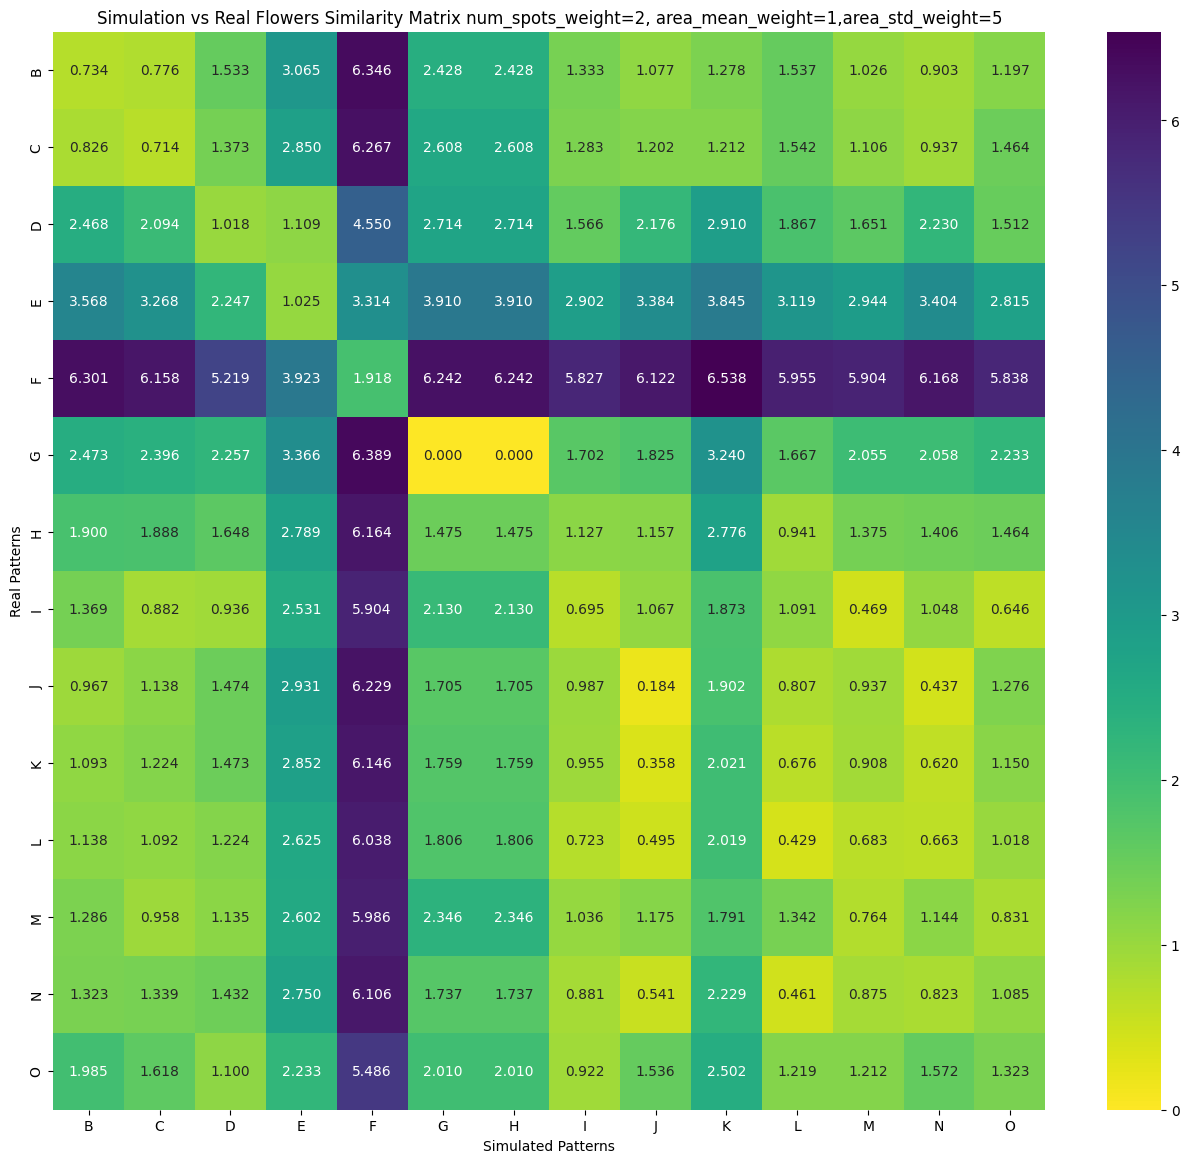

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

In [40]:
scaler = StandardScaler()

feats_arr_scaled = scaler.fit_transform(feats_arr)


# weighting different features: each number corresponds to the subsequengt feature

a = 2
b = 1
c = 5


weights = [
        a, # "num_spots"
        b, # "Area_mean"
        c, # "Area_std"
        1, # "Round_mean"
        1, # "Round_std"
        1, # "rmsd_line_1"
        1, # "rmsd_line_2"
        1, # "rmsd_line_3"
        1, # "rmsd_line_4"
        1 # "rmsd_line_5"

]


for i, weight in enumerate(weights):
  feats_arr_scaled[:,i] *= weight



# compute pairwise RMSD between all 14 real and 14 simulated images

pairwise_mse = np.zeros((14,14))


# iterate through real images
for i in range(0,14):
  real_feats = feats_arr_scaled[i]
  counter = 0
  # iterate through simulated images
  for j in range(14,28):
    sim_feats = feats_arr_scaled[j]
    # real - predicted
    errors = real_feats - sim_feats

    sq_errors = errors ** 2

    mse = np.sqrt(np.mean(sq_errors))


    # each row corresponds to a real image, each column to a simulated imgae (all 1-14 same as the paper)
    pairwise_mse[i][counter] = mse
    counter += 1



plt.figure(figsize=(16,14))

labels = ["B","C","D","E","F","G","H","I","J","K","L","M","N","O"]

sns.heatmap(
    pairwise_mse,
    cmap='viridis_r',
    annot=True,      # show values
    fmt='.3f',        # 2 decimal places
    xticklabels= labels,
    yticklabels= labels
)

plt.title(f'Simulation vs Real Flowers Similarity Matrix num_spots_weight={a}, area_mean_weight={b},area_std_weight={c}')


plt.xlabel("Simulated Patterns")
plt.ylabel("Real Patterns")

# plt.savefig(
#     f"/content/drive/MyDrive/2026-06-11_Revisions-sims_vs_real/Weighted_Heatmaps/num_spots_weight={a}_area_mean_weight={b}_area_std_weight={c}",
#     dpi=600,          # high resolution
#     bbox_inches="tight"
# )

row_diffs = []
col_diffs = []

min_counter = 0

for ind in range(14):
  # calculate the distance between the main identity and the lowest value in the row and column
  row_min = np.min(pairwise_mse[ind,:])
  col_min = np.min(pairwise_mse[:,ind])

  identity_value = pairwise_mse[ind,ind]

  row_diffs.append(identity_value - row_min)
  col_diffs.append(identity_value - col_min)

  # make a list of the number of rows/columns where the identity value is the minimum

  if identity_value - row_min == 0:
    min_counter += 1

  if identity_value - col_min == 0:
    min_counter += 1

min_counters.append(min_counter)
all_row_diffs.append(row_diffs)

all_col_diffs.append(col_diffs)

plt.show()
plt.close
